Crisp dm metodolojisi


In [170]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt

In [171]:
df=pd.read_csv('eksik_data.csv')
df.head()
df.isnull().sum()

ulke        0
boy         0
kilo        0
yas         2
cinsiyet    0
dtype: int64

In [172]:
df['yas']
Q1=np.percentile(df['yas'],25)
Q3=np.percentile(df['yas'],75)
IQR=Q3-Q1
lower_fence=Q1-1.5*IQR
upper_fence=Q3+1.5*IQR
outlier = df[(df['yas'] < lower_fence) | (df['yas'] > upper_fence)]


In [173]:
df['yas'] = df['yas'].fillna(df['yas'].mean())
df['yas']

0     10.00
1     11.00
2     10.00
3      9.00
4     12.00
5     30.00
6     25.00
7     35.00
8     22.00
9     33.00
10    27.00
11    44.00
12    28.45
13    41.00
14    55.00
15    47.00
16    28.45
17    27.00
18    28.00
19    29.00
20    32.00
21    42.00
Name: yas, dtype: float64

## Polinom Regresyon

### 1. Nedir?
**Polinom regresyon**, bağımlı değişken $y$ ile bağımsız değişken $x$ arasındaki **doğrusal olmayan (eğrisel)** ilişkiyi modellemek için kullanılan bir regresyon yöntemidir.

Basit doğrusal regresyon veriye **düz bir çizgi** uydurur:

$$y = \beta_0 + \beta_1 x + \varepsilon$$

Ancak gerçek hayatta pek çok ilişki düz değildir (ör. yaş–maaş, sıcaklık–enerji tüketimi, zaman–büyüme). Polinom regresyon, $x$'in kuvvetlerini modele ekleyerek **eğri** uydurur:

$$y = \beta_0 + \beta_1 x + \beta_2 x^2 + \beta_3 x^3 + \dots + \beta_n x^n + \varepsilon$$

- $n$ → polinomun **derecesi (degree)**
- $\beta_0, \beta_1, \dots, \beta_n$ → modelin öğrendiği katsayılar
- $\varepsilon$ → hata terimi

### 2. Neden hâlâ "doğrusal" model sayılır?
Önemli bir nokta: polinom regresyon **katsayılara göre doğrusaldır**. $x^2, x^3, \dots$ terimlerini yeni özellikler (feature) gibi düşünürsek:

$$x_1 = x,\quad x_2 = x^2,\quad x_3 = x^3 \;\Rightarrow\; y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_3$$

Bu artık bir **çoklu doğrusal regresyondur**. Bu yüzden pratikte iki adım uygulanır:
1. `PolynomialFeatures` ile özellikleri dönüştür ($x \rightarrow [1, x, x^2, \dots, x^n]$)
2. Dönüştürülmüş veriye `LinearRegression` uygula (En Küçük Kareler yöntemi)

### 3. Derece Seçimi: Underfitting vs Overfitting
| Derece | Durum | Açıklama |
|---|---|---|
| Çok düşük (ör. 1) | **Underfitting** (yetersiz öğrenme) | Model veri yapısını yakalayamaz, yüksek bias |
| Uygun (ör. 2–4) | **İyi uyum** | Hem eğitim hem test verisinde başarılı |
| Çok yüksek (ör. 15) | **Overfitting** (aşırı öğrenme) | Gürültüyü ezberler, test verisinde kötü, yüksek varyans |

Doğru dereceyi seçmek için **train/test ayrımı** veya **cross-validation** ile test hatası (RMSE) / $R^2$ karşılaştırılır.

### 4. Avantajlar ve Dezavantajlar
**Avantajlar**
- Eğrisel ilişkileri basitçe modelleyebilir
- Yorumlanması ve uygulanması kolaydır
- Doğrusal regresyonun tüm araçları (OLS, metrikler) kullanılabilir

**Dezavantajlar**
- Yüksek derecelerde overfitting riski
- Aykırı değerlere (outlier) çok duyarlıdır → bu yüzden yukarıda IQR ile outlier analizi önemlidir
- Veri aralığının dışında (extrapolation) tahminler çok saçma olabilir
- Çok değişkenli durumda özellik sayısı hızla patlar

### 5. Dikkat Edilmesi Gerekenler
- Yüksek dereceli terimlerde ($x^{10}$ gibi) değerler çok büyüyebilir → **ölçekleme (`StandardScaler`)** faydalıdır
- Overfitting'i azaltmak için **Ridge / Lasso** gibi düzenlileştirme (regularization) yöntemleri ile birleştirilebilir
- `Pipeline` kullanmak, dönüşüm + model adımlarını tek nesnede toplar ve veri sızıntısını (data leakage) önler

### 6. Değerlendirme Metrikleri
- **MSE / RMSE**: Ortalama (karekök) kare hata — düşük olması iyi
- **MAE**: Ortalama mutlak hata
- **$R^2$**: Modelin açıkladığı varyans oranı (1'e yakın olması iyi)

Aşağıda sentetik bir veri ile adım adım örnek uygulama yer almaktadır.

In [174]:
# 1) Sentetik veri oluştur: eğrisel (kuadratik) ilişki + gürültü
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
np.random.seed(42)
X = np.sort(6 * np.random.rand(100, 1) - 3, axis=0)        # -3 ile 3 arası x
y = 0.5 * X[:, 0]**2 + X[:, 0] + 2 + np.random.randn(100)  # y = 0.5x² + x + 2 + gürültü

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# PolynomialFeatures ne yapıyor? x -> [1, x, x²]
poly = PolynomialFeatures(degree=2)
print("Orijinal x:", X[0])
print("Dönüştürülmüş [1, x, x²]:", poly.fit_transform(X[:1])[0])

Orijinal x: [-2.9668673]
Dönüştürülmüş [1, x, x²]: [ 1.         -2.9668673   8.80230156]


Derece  1 | Train RMSE: 1.630 | Test RMSE: 1.524 | Test R²: 0.381
Derece  2 | Train RMSE: 0.924 | Test RMSE: 0.833 | Test R²: 0.815
Derece 15 | Train RMSE: 0.873 | Test RMSE: 1.259 | Test R²: 0.578


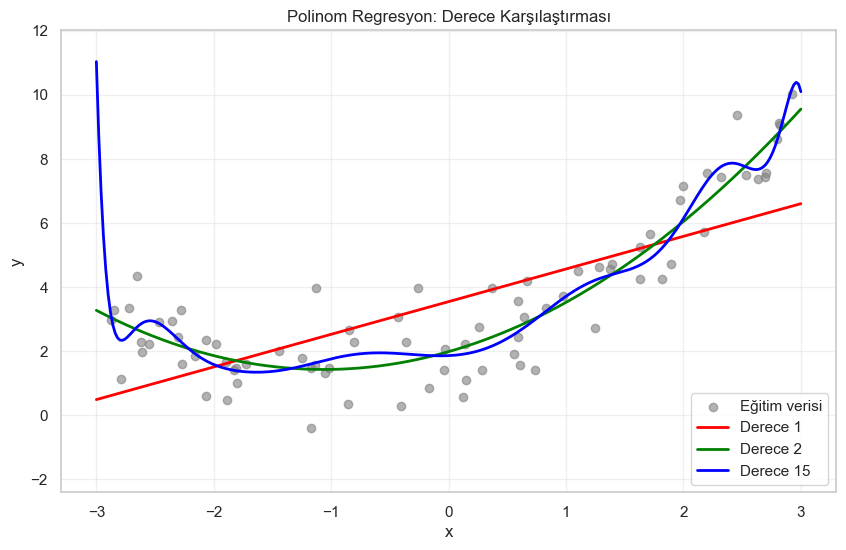


Öğrenilen model: y = 1.98 + 1.05x + 0.49x²


In [175]:
# 2) Farklı derecelerle model kur ve karşılaştır (underfitting / iyi uyum / overfitting)
import matplotlib.pyplot as plt
X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='gray', alpha=0.6, label='Eğitim verisi')

for degree, color in zip([1, 2, 15], ['red', 'green', 'blue']):
    model = make_pipeline(PolynomialFeatures(degree=degree), LinearRegression())
    model.fit(X_train, y_train)

    rmse_train = np.sqrt(mean_squared_error(y_train, model.predict(X_train)))
    rmse_test  = np.sqrt(mean_squared_error(y_test,  model.predict(X_test)))
    r2_test    = r2_score(y_test, model.predict(X_test))
    print(f"Derece {degree:>2} | Train RMSE: {rmse_train:.3f} | Test RMSE: {rmse_test:.3f} | Test R²: {r2_test:.3f}")

    plt.plot(X_plot, model.predict(X_plot), color=color, linewidth=2, label=f'Derece {degree}')

plt.ylim(y.min() - 2, y.max() + 2)
plt.xlabel('x'); plt.ylabel('y')
plt.title('Polinom Regresyon: Derece Karşılaştırması')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# Derece 2 modelinin katsayıları (gerçek değerler: β0=2, β1=1, β2=0.5)
best = make_pipeline(PolynomialFeatures(degree=2), LinearRegression()).fit(X_train, y_train)
lr = best.named_steps['linearregression']
print(f"\nÖğrenilen model: y = {lr.intercept_:.2f} + {lr.coef_[1]:.2f}x + {lr.coef_[2]:.2f}x²")

## Polinom Regresyonda Çoklu Doğrusal Bağlantı (Multicollinearity) ve Ridge Regresyon

---

### 1. Multicollinearity (Çoklu Doğrusal Bağlantı) Nedir?
Bağımsız değişkenlerin (özelliklerin) birbirleriyle **aşırı yüksek korelasyonlu** olması durumudur.
- Klasik regresyonda her bir katsayı ($\beta_j$), *"diğer tüm değişkenler sabit tutulduğunda o değişkenin $y$ üzerindeki tekil etkisi"* olarak yorumlanır.
- Eğer değişkenler birlikte hareket ediyorsa, model hangi etkinin hangi değişkene ait olduğunu matematiksel olarak ayıramaz.

---

### 2. Polinom Regresyonda Neden Kaçınılmazdır? (Yapısal Multicollinearity)
Polinom terimleri bağımsız farklı değişkenler değil, **aynı değişkenin kuvvetleridir**:
$$x, \; x^2, \; x^3, \; x^4, \; \dots, \; x^n$$
Özellikle $x$ pozitif değerlerden oluşuyorsa (ör. yaş, deneyim, fiyat, sıcaklık), $x$ arttıkça $x^2$, $x^3$ ve $x^4$ de kaçınılmaz olarak artar. Bu durum değişkenler arasında **0.95 – 0.999** düzeyinde devasa korelasyonlar yaratır. Buna literatürde **yapısal çoklu doğrusal bağlantı (structural multicollinearity)** denir.

---

### 3. Multicollinearity Polinom Fonksiyonda Ne Yapar? (Zararları)

| Etki | Açıklama |
|---|---|
| **Katsayı Patlaması (Coefficients Explosion)** | Model eğriyi uydurmaya çalışırken zıt işaretli devasa katsayılar üretir (ör. $\beta_2 = +5400$, $\beta_3 = -5900$). Artı ve eksi birbirini nötrlemeye çalışır. |
| **Aşırı Varyans ve Overfitting** | Verideki minicik bir gürültü veya tek bir veri noktasının değişmesi katsayıları altüst eder. Model eğitim verisindeki noktaları tutturmak için çılgınca zikzaklar çizer, test verisinde çuvallar. |
| **Matrisel Kararsızlık (Ill-Conditioned Matrix)** | Katsayılar analitik olarak $\beta = (X^T X)^{-1} X^T y$ formülüyle çözülür. Sütunlar neredeyse birbirinin katı olduğunda $X^T X$ matrisinin determinantı 0'a çok yaklaşır. Bilgisayar matrisin tersini alırken sayısal yuvarlama hataları ve kararsızlık tavan yapar. |
| **Yorumlanabilirlik Sıfırlanır** | Katsayıların standart hataları şişer, p-değerleri anlamsızlaşır; hangi terimin gerçekten etkili olduğunu söylemek imkansızlaşır. |

> ⚠️ **Özet:** Multicollinearity eğitim seti üzerinde $R^2$'yi düşürmez (hatta sahte bir yükseklik verir), ancak katsayıları çıldırtarak modelin **genelleme gücünü (test performansını)** yok eder.

---

### 4. Ridge Regresyon (L2 Regularization) Nedir ve Ne Yapar?

Ridge regresyon, klasik regresyonun hata fonksiyonuna katsayıların karelerinin toplamını bir **ceza (penalty)** terimi olarak ekler:

$$\text{Maliyet (Cost)} = \sum_{i=1}^m \left(y_i - \hat{y}_i\right)^2 + \alpha \sum_{j=1}^p \beta_j^2 = \text{MSE} + \alpha \|\beta\|_2^2$$

- **$\alpha$ (Alpha / Lambda):** Düzenlileştirme şiddetini belirleyen hiperparametredir.
  - $\alpha = 0$: Klasik Doğrusal Regresyon (OLS). Ceza yok, katsayılar patlamaya açık.
  - $\alpha \to \infty$: Bütün katsayılar sıfıra yaklaşır (aşırı basitleşme / underfitting).
  - Doğru $\alpha$: Çapraz doğrulama (**Cross-Validation**) ile belirlenir.

#### Ridge Ne Yapar? (Multicollinearity Panzehiri)
1. **Katsayı Büzülmesi (Shrinkage):** Ceza terimi sayesinde katsayıların devasa boyutlara (+5000, -5000 gibi) fırlamasını engeller, onları sıfıra doğru çeker ve dizginler. (Not: Katsayıları küçültür ama Lasso gibi tamamen sıfır yapmaz).
2. **Matrisel Düzeltme (Tersi Alınabilirlik):** Ridge'in matematiksel çözümü şöyledir:
   $$\beta_{\text{ridge}} = \left( X^T X + \alpha I \right)^{-1} X^T y$$
   Burada $I$ birim matristir. Köşegene eklenen pozitif $\alpha$ değeri sayesinde, daha önce tekil (singular) veya tersi alınması kararsız olan $X^T X$ matrisi **kesinlikle tersi alınabilir ve kararlı** hale gelir.
3. **Varyansı Düşürür (Bias-Variance Dengesi):** Modele çok ufak bir yanlılık (bias) katar, ancak varyansı (dalgalanmayı ve aşırı ezberlemeyi) dramatik şekilde düşürür. Böylece test hatası minimuma iner.

---

### 5. Kritik Kural: Standartlaştırma (StandardScaler) Neden Şarttır?
Ridge ceza teriminde $\sum \beta_j^2$ kullanır. Yani **katsayının mutlak büyüklüğüne** bakar:
- $x \in [1, 5]$ iken $x^5 \in [1, 3125]$ olur.
- Ölçeklendirme yapılmazsa, $x^5$ sütunundaki sayılar çok büyük olduğu için onun katsayısı doğal olarak çok küçük çıkar ve Ridge ona neredeyse hiç ceza kesmez; tam tersine küçük ölçekli $x$ sütununa haksız ceza keser!
- **Kural:** Polinom + Ridge uygulanırken **MUTLAKA** önce özellikler standartlaştırılmalıdır (`StandardScaler`).

---

### 6. Nasıl Yapılır? (İdeal İş Akışı)
1. Özellikleri türet: `PolynomialFeatures(degree=d)`
2. Özellikleri standartlaştır: `StandardScaler()`
3. Ridge modelini en iyi $\alpha$ ile kur: `RidgeCV(alphas=...)`
4. Hepsini veri sızıntısını (data leakage) önlemek için tek bir `Pipeline` içine al.

Aşağıdaki kod hücresinde multicollinearity kanıtı, OLS'in katsayı patlaması ve Ridge'in bunu nasıl pürüzsüzleştirdiği uygulamalı olarak gösterilmiştir.

1. POLİNOM DERECELERİ ARASINDAKİ KORELASYON (Multicollinearity Kanıtı):
       x^1    x^2    x^3    x^4
x^1  1.000  0.978  0.934  0.886
x^2  0.978  1.000  0.987  0.960
x^3  0.934  0.987  1.000  0.992
x^4  0.886  0.960  0.992  1.000
-> Görüldüğü gibi x ile x^2, x^3 arasında 0.90 - 0.99 korelasyon vardır!

2. KATSAYILARIN KARŞILAŞTIRILMASI (Derece = 7):
     OLS Katsayıları (Patlayan)  Ridge Katsayıları (Büzülmüş)
x^1                     -199.14                          2.47
x^2                     1629.17                          2.29
x^3                    -5888.89                          1.51
x^4                    11678.29                          0.74
x^5                   -13018.20                          0.18
x^6                     7640.12                         -0.14
x^7                    -1834.89                         -0.28

RidgeCV tarafından seçilen ideal alpha: 0.4942

3. TEST SETİ PERFORMANSLARI:
OLS (Doğrusal)  -> Test RMSE: 1.422 | Test R²: 0.948
Ridge (L2)      -> 

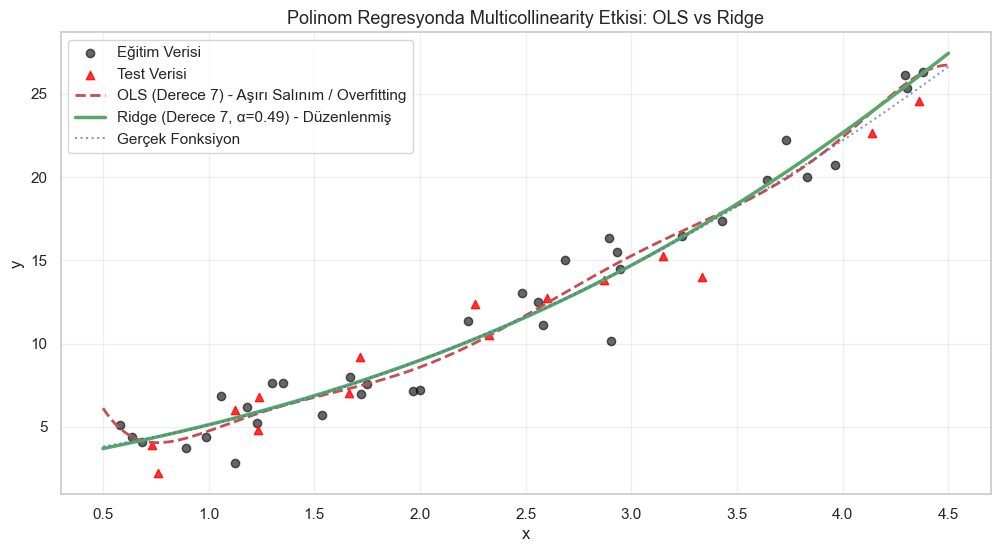

In [176]:
# ==============================================================================
# POLİNOM REGRESYONDA MULTICOLLINEARITY & RIDGE REGRESYON UYGULAMASI
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

# 1) Veri Üretimi (Kuadratik ilişki + gürültü)
np.random.seed(42)
X = np.sort(np.random.uniform(0.5, 4.5, 50)).reshape(-1, 1)
y = 3.0 + 1.2 * X[:, 0] + 0.9 * X[:, 0]**2 + np.random.normal(0, 1.5, 50)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# ------------------------------------------------------------------------------
# ADIM 1: MULTICOLLINEARITY TESPİTİ (Korelasyon Matrisi)
# ------------------------------------------------------------------------------
poly_sample = PolynomialFeatures(degree=4, include_bias=False)
X_poly_sample = poly_sample.fit_transform(X)
corr_matrix = pd.DataFrame(X_poly_sample, columns=[f'x^{i}' for i in range(1, 5)]).corr()

print("="*60)
print("1. POLİNOM DERECELERİ ARASINDAKİ KORELASYON (Multicollinearity Kanıtı):")
print("="*60)
print(corr_matrix.round(3))
print("-> Görüldüğü gibi x ile x^2, x^3 arasında 0.90 - 0.99 korelasyon vardır!\n")

# ------------------------------------------------------------------------------
# ADIM 2: YÜKSEK DERECELİ MODELLEME (Derece = 7)
# OLS (Linear Regression) vs Ridge (L2 Regularization)
# ------------------------------------------------------------------------------
degree = 7

# Model A: Standart OLS Regresyon (StandardScaler ile birlikte)
pipe_ols = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('ols', LinearRegression())
])
pipe_ols.fit(X_train, y_train)

# Model B: StandardScaler + RidgeCV (En iyi alpha otomatik seçilir)
alphas = np.logspace(-3, 3, 50)
pipe_ridge = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', RidgeCV(alphas=alphas, cv=5))
])
pipe_ridge.fit(X_train, y_train)
best_alpha = pipe_ridge.named_steps['ridge'].alpha_

# ------------------------------------------------------------------------------
# ADIM 3: KATSAYILARIN KARŞILAŞTIRILMASI (Katsayı Patlaması vs Büzülme)
# ------------------------------------------------------------------------------
coef_df = pd.DataFrame({
    'OLS Katsayıları (Patlayan)': pipe_ols.named_steps['ols'].coef_,
    'Ridge Katsayıları (Büzülmüş)': pipe_ridge.named_steps['ridge'].coef_
}, index=[f'x^{i}' for i in range(1, degree + 1)])

print("="*60)
print(f"2. KATSAYILARIN KARŞILAŞTIRILMASI (Derece = {degree}):")
print("="*60)
print(coef_df.round(2))
print(f"\nRidgeCV tarafından seçilen ideal alpha: {best_alpha:.4f}\n")

# ------------------------------------------------------------------------------
# ADIM 4: TEST PERFORMANSI
# ------------------------------------------------------------------------------
rmse_ols = np.sqrt(mean_squared_error(y_test, pipe_ols.predict(X_test)))
r2_ols = r2_score(y_test, pipe_ols.predict(X_test))

rmse_ridge = np.sqrt(mean_squared_error(y_test, pipe_ridge.predict(X_test)))
r2_ridge = r2_score(y_test, pipe_ridge.predict(X_test))

print("="*60)
print("3. TEST SETİ PERFORMANSLARI:")
print("="*60)
print(f"OLS (Doğrusal)  -> Test RMSE: {rmse_ols:.3f} | Test R²: {r2_ols:.3f}")
print(f"Ridge (L2)      -> Test RMSE: {rmse_ridge:.3f} | Test R²: {r2_ridge:.3f}")

# ------------------------------------------------------------------------------
# ADIM 5: GÖRSELLEŞTİRME (Overfitting vs Ridge Pürüzsüzlüğü)
# ------------------------------------------------------------------------------
X_grid = np.linspace(0.5, 4.5, 300).reshape(-1, 1)

plt.figure(figsize=(12, 6))
plt.scatter(X_train, y_train, color='black', alpha=0.6, label='Eğitim Verisi')
plt.scatter(X_test, y_test, color='red', alpha=0.8, marker='^', label='Test Verisi')

plt.plot(X_grid, pipe_ols.predict(X_grid), 'r--', linewidth=2, label=f'OLS (Derece {degree}) - Aşırı Salınım / Overfitting')
plt.plot(X_grid, pipe_ridge.predict(X_grid), 'g-', linewidth=2.5, label=f'Ridge (Derece {degree}, α={best_alpha:.2f}) - Düzenlenmiş')

# Gerçek fonksiyon eğrisi
y_true = 3.0 + 1.2 * X_grid[:, 0] + 0.9 * X_grid[:, 0]**2
plt.plot(X_grid, y_true, 'b:', linewidth=1.5, alpha=0.7, label='Gerçek Fonksiyon')

plt.title('Polinom Regresyonda Multicollinearity Etkisi: OLS vs Ridge', fontsize=13)
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [177]:
#ridge hatayı minimize eder  lasso çoğu değeri 0 yapar
#lasso da max_iter kullanılır .genelde 100k olur

## GridSearchCV (Grid Search Cross-Validation)

---

### 1. Nedir ve Ne Yapar?
Modelin performansını en üst düzeye çıkaran **en iyi hiperparametre kombinasyonunu** bulmak için kullanılan kapsamlı bir arama yöntemidir. 
- Belirlediğimiz parametre aralıklarının (ör. polinom derecesi: 1, 2, 3 ve Ridge $\alpha$: 0.01, 1, 10) **tüm olası kombinasyonlarını (kartezyen çarpımını)** tek tek dener.
- Her kombinasyonu **K-Katlı Çapraz Doğrulama (K-Fold CV)** ile test eder.
- En yüksek skoru veren en iyi modeli otomatik olarak seçip tüm eğitim verisiyle yeniden eğitir.

---

### 2. Parametreler Ne İşe Yarar?

| Parametre | Ne İşe Yarar? / Açıklama |
|---|---|
| **`estimator`** | Hiperparametreleri optimize edilecek model veya `Pipeline` nesnesidir (ör. `Ridge()`, `Lasso()`, `Pipeline(...)`). |
| **`param_grid`** | Denenecek parametre isimlerini ve değer listelerini içeren bir sözlüktür (`dict`). *Pipeline kullanılıyorsa format: `{'adımAdı__parametreAdı': [liste]}` (ör. `'poly__degree': [1, 2, 3]`).* |
| **`cv`** | Çapraz doğrulama (Cross-Validation) kat sayısıdır (ör. `cv=5` $\rightarrow$ veriyi 5 eşit parçaya böler; her seferinde 4 parçayla eğitip 1 parçayla test eder). |
| **`scoring`** | En iyi modeli belirlerken optimize edilecek başarı metriğidir (ör. regresyon için `'neg_mean_squared_error'`, `'r2'`; sınıflandırma için `'accuracy'`, `'f1'`, `'roc_auc'`). *Not: Scikit-learn optimizasyonda maksimize etmeye çalıştığı için MSE skoru eksi (`neg_`) işaretle döner.* |
| **`n_jobs`** | Aramanın kaç işlemci çekirdeğinde paralel çalışacağını belirler. `n_jobs=-1` verilirse bilgisayarın tüm CPU çekirdekleri kullanılır ve arama ciddi şekilde hızlanır. |
| **`verbose`** | Arama sırasında ekrana basılacak bilgi/log detay seviyesidir (`0`: sessiz, `1`: kaç deneme yapıldığını söyler, `2`: süre ve fold detaylarını gösterir). |
| **`return_train_score`** | `True` yapılırsa sadece test skorunu değil, her denemedeki eğitim seti skorunu da kaydeder (aşırı öğrenme / overfitting kontrolü için faydalıdır). |

---

### 3. Önemli Çıktı Nitelikleri (Attributes)

| Nitelik | Anlamı |
|---|---|
| **`grid.best_params_`** | En yüksek skoru veren en iyi parametre kombinasyonu sözlüğü. |
| **`grid.best_score_`** | En iyi kombinasyonun çapraz doğrulama (CV) başarı ortalaması. |
| **`grid.best_estimator_`** | En iyi parametrelerle eğitilmiş, doğrudan `predict()` çağrılabilen hazır nihai model. |
| **`grid.cv_results_`** | Denediği tüm kombinasyonların skorlarını, sürelerini içeren detaylı tablo (`pd.DataFrame(grid.cv_results_)` ile incelenebilir). |

In [178]:
# ==============================================================================
# GridSearchCV KULLANIMI: Polinom Derecesi ve Ridge Alfa Optimizasyonu
# ==============================================================================
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

# 1. Pipeline Tanımlama (Adım adları: 'poly', 'scaler', 'ridge')
pipeline = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

# 2. Denenecek Parametre Izgarası (param_grid)
# Not: Pipeline içindeki adımlara erişmek için 'adımAdı__parametreAdı' kullanılır
param_grid = {
    'poly__degree': [1, 2, 3, 5, 7],                      # Hangi polinom derecesi en iyi?
    'ridge__alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0] # Hangi ceza katsayısı en iyi?
}

# 3. GridSearchCV Modelini Başlatma
grid = GridSearchCV(
    estimator=pipeline,                   # Optimize edilecek model/pipeline
    param_grid=param_grid,                # Denenecek parametre sözlüğü
    cv=5,                                 # 5-Katlı Çapraz Doğrulama (K-Fold CV)
    scoring='neg_mean_squared_error',     # Regresyonda MSE minimizasyonu
    n_jobs=-1,                            # Tüm CPU çekirdeklerini kullan (hızlı)
    verbose=1                             # İlerleme durumunu göster
)

# 4. Aramayı Başlatma (Fitting)
grid.fit(X_train, y_train)

# 5. En İyi Sonuçları Yazdırma
print("="*55)
print("En İyi Parametreler :", grid.best_params_)
print(f"En İyi CV Skoru (MSE): {-grid.best_score_:.4f}")
print("="*55)

# 6. En İyi Model ile Test Seti Tahmini
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(f"Test Seti RMSE       : {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Test Seti R²         : {r2_score(y_test, y_pred):.4f}")


Fitting 5 folds for each of 30 candidates, totalling 150 fits
En İyi Parametreler : {'poly__degree': 2, 'ridge__alpha': 0.01}
En İyi CV Skoru (MSE): 2.1638
Test Seti RMSE       : 1.3819
Test Seti R²         : 0.9512


In [179]:
from sklearn.linear_model import Ridge
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

data = fetch_california_housing(as_frame=True)
X = data.data
y = data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Ridge(alpha=1.0) modelini kur
ridge_model = Ridge(alpha=1.0)

# 2. Modeli X_train, y_train ile eğit
ridge_model.fit(X_train, y_train)

# 3. Test R² hesapla ve yazdır (Ridge sınıfının .score metodu varsayılan olarak R² döndürür)
r2_score = ridge_model.score(X_test, y_test)
print(f"Test R² Skoru: {r2_score:.4f}")

Test R² Skoru: 0.5759


In [180]:
df=pd.read_csv('maas.csv')
df

,unvan,Egitim Seviyesi,maas
0,Cayci,1,2250
1,Sekreter,2,2500
2,Uzman Yardimcisi,3,3000
3,Uzman,4,4000
4,Proje Yoneticisi,5,5500
5,Sef,6,7500
6,Mudur,7,10000
7,Direktor,8,15000
8,C-level,9,25000
9,CEO,10,50000


In [181]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression

# 1. Veriyi 2 boyutlu olarak seçin
X = df[['Egitim Seviyesi']] 
y = df['maas']

# 2. Bölme
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Pipeline & Eğitim
model = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)

# 4. Değerlendirme
r2 = model.score(X_test, y_test)
print(f"R² Skoru: {r2:.2%}")


R² Skoru: 76.66%


## Lojistik Regresyon (Logistic Regression)

---

### 1. Nedir ve Ne Yapar?
Adında "regresyon" geçmesine rağmen **ikili (binary) veya çok sınıflı sınıflandırma (classification)** problemlerinde kullanılan doğrusal bir sınıflandırma algoritmasıdır.
- Doğrusal regresyon gibi girdilerin ağırlıklı toplamını hesaplar: $z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$
- Ancak sonucu doğrudan çıktı olarak vermek yerine **Sigmoid (Lojistik) Fonksiyonu**'ndan geçirerek $[0, 1]$ aralığında bir **olasılığa ($P$)** dönüştürür:
  $$P(y=1|x) = \sigma(z) = \frac{1}{1 + e^{-z}}$$
- **Karar Eşiği (Threshold - Varsayılan 0.5):**
  - $P \ge 0.5 \implies$ Sınıf 1 (Örn: Erkek / Pozitif)
  - $P < 0.5 \implies$ Sınıf 0 (Örn: Kadın / Negatif)

---

### 2. Neden Doğrusal Regresyon Yerine Lojistik Regresyon?
1. **Olasılık Sınırları:** Doğrusal regresyon $-\infty$ ile $+\infty$ arasında değerler üretebilir. Sigmoid ise çıktıyı kesinlikle $[0, 1]$ aralığına hapseder.
2. **Aykırı Değerler (Outliers):** Doğrusal regresyon aykırı değerlerden hızla etkilenip karar sınırını kaydırır; lojistik regresyon sigmoid doyum noktaları sayesinde uç değerlere karşı çok daha kararlıdır.
3. **Maliyet Fonksiyonu (Log-Loss / Cross-Entropy):** Parametreler En Küçük Kareler (OLS) yerine **Maksimum Olabilirlik Kestirimi (Maximum Likelihood Estimation - MLE)** ile optimize edilir.

---

### 3. Önemli Parametreler
- **`C` (Düzenlileştirme Ters Katsayısı):** Ridge/Lasso'daki ceza katsayısının tersidir ($C = 1/\alpha$). Küçük $C$ güçlü düzenlileştirme (underfitting riski), büyük $C$ zayıf düzenlileştirme (overfitting riski) anlamına gelir. Varsayılan `1.0`.
- **`max_iter`:** Optimizasyon algoritmasının yakınsaması için izin verilen maksimum adım sayısıdır (`1000` önerilir).
- **`StandardScaler`:** Özelliklerin farklı birimlerde olması durumunda katsayıların doğru öğrenilmesi için lojistik regresyonda ölçekleme **şarttır**.

LOJİSTİK REGRESYON MODEL PERFORMANSI
Doğruluk (Accuracy)    : %83.33
Hassasiyet (Precision) : %100.00
Duyarlılık (Recall)    : %66.67
F1 Skoru               : %80.00

Sınıflandırma Raporu (Classification Report):
              precision    recall  f1-score   support

   Kadın (0)       0.75      1.00      0.86         3
   Erkek (1)       1.00      0.67      0.80         3

    accuracy                           0.83         6
   macro avg       0.88      0.83      0.83         6
weighted avg       0.88      0.83      0.83         6

Yeni Örnek Tahmini (Boy: 182, Kilo: 82, Yaş: 26):
Tahmin Edilen Sınıf   : Erkek
Kadın Olma Olasılığı  : %27.58
Erkek Olma Olasılığı  : %72.42


c:\Users\admin123\anaconda3\Lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


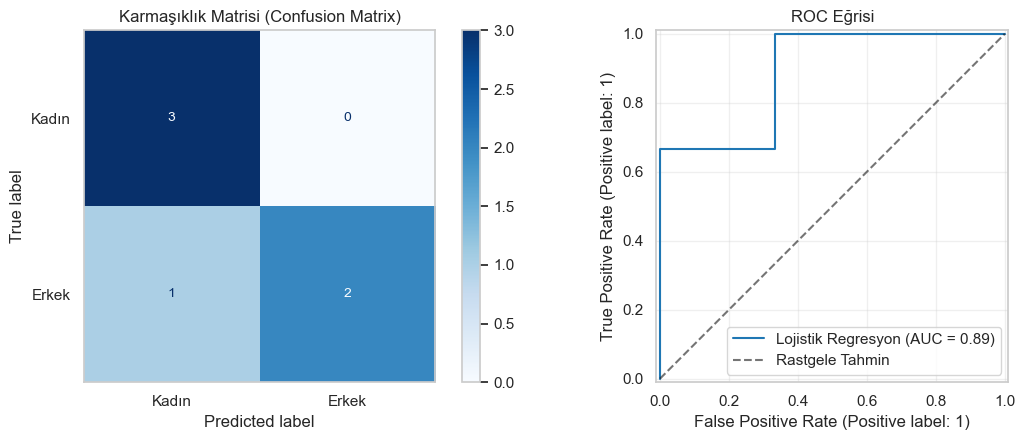

In [182]:
# ==============================================================================
# LOJİSTİK REGRESYON: Boy, Kilo ve Yaş ile Cinsiyet Sınıflandırması
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)

# 1. Veri Yükleme (data.csv)
df_cinsiyet = pd.read_csv('data.csv')

# 2. Özellikler (X) ve Hedef Değişken (y)
X = df_cinsiyet[['boy', 'kilo', 'yas']]
y = df_cinsiyet['cinsiyet'].map({'k': 0, 'e': 1})  # Kadın: 0, Erkek: 1

# 3. Train-Test Ayrımı (stratify=y ile sınıf dağılımı korunur)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 4. Pipeline Tanımlama (Ölçekleme + Lojistik Regresyon)
model_logreg = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(C=1.0, max_iter=1000, random_state=42))
])

# 5. Modeli Eğitme
model_logreg.fit(X_train, y_train)

# 6. Test Seti Tahminleri (Sınıf ve Olasılık Değerleri)
y_pred = model_logreg.predict(X_test)
y_proba = model_logreg.predict_proba(X_test)[:, 1]  # 1 (Erkek) olma olasılığı

# 7. Başarı Metrikleri
print("=" * 60)
print("LOJİSTİK REGRESYON MODEL PERFORMANSI")
print("=" * 60)
print(f"Doğruluk (Accuracy)    : %{accuracy_score(y_test, y_pred)*100:.2f}")
print(f"Hassasiyet (Precision) : %{precision_score(y_test, y_pred, zero_division=0)*100:.2f}")
print(f"Duyarlılık (Recall)    : %{recall_score(y_test, y_pred, zero_division=0)*100:.2f}")
print(f"F1 Skoru               : %{f1_score(y_test, y_pred, zero_division=0)*100:.2f}")
print("\nSınıflandırma Raporu (Classification Report):")
print(classification_report(y_test, y_pred, target_names=['Kadın (0)', 'Erkek (1)'], zero_division=0))

# 8. Yeni Bir Örnek İçin Tahmin
yeni_kisi = pd.DataFrame({'boy': [182], 'kilo': [82], 'yas': [26]})
tahmin_sinif = model_logreg.predict(yeni_kisi)[0]
tahmin_olasilik = model_logreg.predict_proba(yeni_kisi)[0]

print("=" * 60)
print(f"Yeni Örnek Tahmini (Boy: 182, Kilo: 82, Yaş: 26):")
print(f"Tahmin Edilen Sınıf   : {'Erkek' if tahmin_sinif == 1 else 'Kadın'}")
print(f"Kadın Olma Olasılığı  : %{tahmin_olasilik[0]*100:.2f}")
print(f"Erkek Olma Olasılığı  : %{tahmin_olasilik[1]*100:.2f}")
print("=" * 60)

# 9. Görselleştirme: Karmaşıklık Matrisi ve ROC Eğrisi
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Karmaşıklık Matrisi (Confusion Matrix)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Kadın', 'Erkek'],
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title('Karmaşıklık Matrisi (Confusion Matrix)')
axes[0].grid(False)

# ROC Eğrisi
RocCurveDisplay.from_estimator(
    model_logreg, X_test, y_test,
    name='Lojistik Regresyon',
    color='tab:blue',
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Rastgele Tahmin')
axes[1].set_title('ROC Eğrisi')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

1. LogisticRegression İçinde Olasılık TahminiLojistik regresyon, modelin ürettiği doğrusal çıktıyı ($z = w^T x + b$) sigmoid fonksiyonundan geçirerek $0$ ile $1$ arasında bir olasılığa dönüştürür. predict_proba metodu doğrudan bu sigmoid sonucunu döndürür:

In [183]:
from sklearn.linear_model import LogisticRegression
import numpy as np

# Örnek veri seti
X = np.array([[-2.0], [-1.0], [1.0], [2.0]])
y = np.array([0, 0, 1, 1])

clf = LogisticRegression()
clf.fit(X, y)

# Sigmoid çıktısı (sınıf olasılıkları)
olasiliklar = clf.predict_proba([[0.5]])
print(olasiliklar)  # [[0.41, 0.59]] -> 2. sütun pozitif sınıfın sigmoid çıktısıdır

[[0.37676656 0.62323344]]


In [184]:
from sklearn.metrics import log_loss
import numpy as np

y_true = np.array([1, 0, 1, 1, 0])
y_pred = np.array([0.9, 0.1, 0.8, 0.35, 0.2])

loss = log_loss(y_true, y_pred)
print("Scikit-learn Log Loss:", loss)

Scikit-learn Log Loss: 0.34136605168855


In [185]:
from sklearn.metrics import log_loss
y_true = [1, 0, 1, 0]
yA = [0.8, 0.3, 0.6, 0.2]
yB = [0.6, 0.4, 0.7, 0.3]
# her ikisinin log_loss değerini yazdırın ve düşük olanı yorumlayın
los=log_loss(y_true,yA)
los1=log_loss(y_true,yB)
if los>los1:
    print('los1 daha iyidir')
else:
    print('los daha iyidir')



los daha iyidir


Temel Mantık: Eşik Değeri (Threshold) Nedir?
Lojistik regresyon veya sinir ağları doğrudan "0" veya "1" tahmin etmez; $0$ ile $1$ arasında bir olasılık üretir ($P(y=1)$).
Varsayılan olarak kabul edilen sınır 0.50'dir:$P \ge 0.50 \rightarrow$ Pozitif Sınıf (1)$P < 0.50 \rightarrow$ Negatif Sınıf (0)Ancak 0.50 her problem için ideal değildir. Bu eşiği yukarı veya aşağı çekmek modelin hata türlerini doğrudan etkiler.Eşiği Değiştirince Ne Olur?Eşik HareketiNe Anlama Gelir?Precision (Kesinlik)Recall (Duyarlılık)Hata EğilimiEşiği Artırmak (örn. 0.80)Model sadece çok emin olduğu örneklere "1" der.Artar (Daha az yanlış pozitif / FP)Düşer (Daha fazla kaçırılan vaka / FN)Muhafazakâr tahminEşiği Düşürmek (örn. 0.20)Model en ufak şüphede bile örneğe "1" der.Düşer (Daha fazla yanlış pozitif / FP)Artar (Neredeyse hiç vaka kaçırmaz / FN azalır)Agresif tahminGerçek Hayat ÖrnekleriKanser / Hastalık Teşhisi: Hastalığı kaçırmak (False Negative) ölümcül olabilir. Bu yüzden eşik değeri düşürülür (örn. 0.20). Sağlıklı birine fazladan test yapılması göze alınır, yeter ki hasta kimse gözden kaçmasın (Yüksek Recall hedeflenir).Spam Filtresi: Önemli bir iş teklifini spam kutusuna atmak (False Positive) kullanıcı için çok kötüdür. Bu yüzden eşik yükseltilir (örn. 0.85). Model bir e-postayı spama atacaksa bundan kesinlikle emin olmalıdır (Yüksek Precision hedeflenir).

In [186]:
import numpy as np

# Modelin pozitif sınıf (1) için ürettiği olasılıklar
y_probs = np.array([0.15, 0.42, 0.55, 0.78, 0.91])

# 1. Varsayılan eşik (0.50)
y_pred_default = (y_probs >= 0.50).astype(int)
print("Eşik 0.50:", y_pred_default)  # [0, 0, 1, 1, 1]

# 2. Düşük eşik (0.30) -> Recall artar
y_pred_low = (y_probs >= 0.30).astype(int)
print("Eşik 0.30:", y_pred_low)      # [0, 1, 1, 1, 1]

# 3. Yüksek eşik (0.80) -> Precision artar
y_pred_high = (y_probs >= 0.80).astype(int)
print("Eşik 0.80:", y_pred_high)     # [0, 0, 0, 1, 1]

Eşik 0.50: [0 0 1 1 1]
Eşik 0.30: [0 1 1 1 1]
Eşik 0.80: [0 0 0 0 1]


In [187]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, log_loss

# 1. Veri Hazırlığı
X, y = load_iris(return_X_y=True)
X = X[y != 2]
y = y[y != 2]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Model ve Eğitim
model = Pipeline([
    ('log_reg', LogisticRegression())
])
model.fit(X_train, y_train)

# 3. Olasılık Çıktıları (Sigmoid)
# predict_proba: [P(y=0), P(y=1)] döner, 1. indeks pozitif sınıfın olasılığıdır
y_probs = model.predict_proba(X_test)[:, 1]

# 4. Log Loss Hesabı
kayip = log_loss(y_test, y_probs)
print(f"Log Loss Değeri: {kayip:.4f}")

# 5. Threshold Trade-off (Eşik Değiştirme)
# Varsayılan 0.50 eşiği yerine özel eşikler tanımlayalım:
esik_yuksek = 0.80  # Precision artar, Recall düşer
esik_dusuk = 0.20   # Recall artar, Precision düşer

y_pred_default = (y_probs >= 0.50).astype(int)  # model.predict(X_test) ile aynıdır
y_pred_high = (y_probs >= esik_yuksek).astype(int)
y_pred_low = (y_probs >= esik_dusuk).astype(int)

# 6. Sonuçların İncelenmesi
print("\n--- Varsayılan Eşik (0.50) Raporu ---")
print(classification_report(y_test, y_pred_default))

Log Loss Değeri: 0.0213

--- Varsayılan Eşik (0.50) Raporu ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00         8

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



In [188]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
X, y = load_iris(return_X_y=True)
y = (y == 0).astype(int)  # setosa = 1, diğer = 0
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

model=Pipeline([
  ('scaler',StandardScaler()),
  ('loss_leg',LogisticRegression())
])
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
acc=accuracy_score(y_test,y_pred)
print(f'acc:{acc:.2f}')
# Pipeline kurup test accuracy yazdırın

acc:1.00


--- İKİLİ SINIFLANDIRMA SONUÇLARI ---
Confusion Matrix:
 [[4 1]
 [2 3]]
True Negative  (TN): 4
False Positive (FP): 1 (Tip I Hata / Yanlış Alarm)
False Negative (FN): 2 (Tip II Hata / Kaçırılan Vaka)
True Positive  (TP): 3

Hesaplanan Accuracy : 0.7000
Hesaplanan Precision: 0.7500
Hesaplanan Recall   : 0.6000

--- NORMALİZASYON ÖRNEKLERİ ---
Satır Bazlı Normalizasyon (normalize='true'):
 [[0.8 0.2]
 [0.4 0.6]]
Sütun Bazlı Normalizasyon (normalize='pred'):
 [[0.667 0.25 ]
 [0.333 0.75 ]]

--- ÇOK SINIFLI KATEGORİK MATRİS ---
Sıralama: ['kedi', 'köpek', 'kuş']
[[2 1 0]
 [0 1 1]
 [0 0 1]]

--- IRIS MODEL PERFORMANSI ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91      

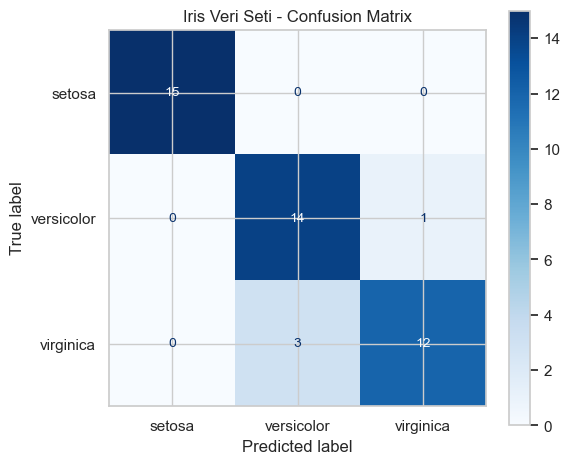

In [189]:
"""
Scikit-Learn Karmaşıklık Matrisi (Confusion Matrix) Kapsamlı Rehberi
===================================================================
Bu script, `confusion_matrix` fonksiyonunun temel kullanımından çok sınıflı
analize, normalizasyondan görselleştirmeye kadar tüm yönlerini içerir.
"""

# ==========================================
# 1. Kütüphanelerin Yüklenmesi
# ==========================================
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ==========================================
# 2. İkili (Binary) Sınıflandırma ve Unpacking
# ==========================================
# Sentetik ikili etiketler ve model tahminleri
y_true_binary = np.array([0, 1, 0, 1, 0, 0, 1, 1, 1, 0])
y_pred_binary = np.array([0, 1, 0, 0, 0, 1, 1, 1, 0, 0])

# Karmaşıklık matrisinin hesaplanması
cm_binary = confusion_matrix(y_true_binary, y_pred_binary)

# 2x2 matristen TN, FP, FN, TP değerlerini ravel() ile ayrıştırma
tn, fp, fn, tp = cm_binary.ravel()

print("--- İKİLİ SINIFLANDIRMA SONUÇLARI ---")
print("Confusion Matrix:\n", cm_binary)
print(f"True Negative  (TN): {tn}")
print(f"False Positive (FP): {fp} (Tip I Hata / Yanlış Alarm)")
print(f"False Negative (FN): {fn} (Tip II Hata / Kaçırılan Vaka)")
print(f"True Positive  (TP): {tp}")

# Temel metriklerin formüllerle doğrulanması
hesaplanan_precision = tp / (tp + fp)
hesaplanan_recall = tp / (tp + fn)
hesaplanan_accuracy = (tp + tn) / (tp + tn + fp + fn)

print(f"\nHesaplanan Accuracy : {hesaplanan_accuracy:.4f}")
print(f"Hesaplanan Precision: {hesaplanan_precision:.4f}")
print(f"Hesaplanan Recall   : {hesaplanan_recall:.4f}")

# ==========================================
# 3. Normalizasyon Seçenekleri
# ==========================================
# normalize='true' -> Gerçek sınıfların (satırların) oranını verir (Recall odaklı)
cm_norm_true = confusion_matrix(y_true_binary, y_pred_binary, normalize="true")

# normalize='pred' -> Tahmin sınıflarının (sütunların) oranını verir (Precision odaklı)
cm_norm_pred = confusion_matrix(y_true_binary, y_pred_binary, normalize="pred")

# normalize='all'  -> Toplam örnek sayısına böler
cm_norm_all = confusion_matrix(y_true_binary, y_pred_binary, normalize="all")

print("\n--- NORMALİZASYON ÖRNEKLERİ ---")
print("Satır Bazlı Normalizasyon (normalize='true'):\n", np.round(cm_norm_true, 3))
print("Sütun Bazlı Normalizasyon (normalize='pred'):\n", np.round(cm_norm_pred, 3))

# ==========================================
# 4. Çok Sınıflı (Multiclass) Metin Etiketleri
# ==========================================
y_true_text = ["kedi", "köpek", "kedi", "kuş", "köpek", "kedi"]
y_pred_text = ["kedi", "kuş", "kedi", "kuş", "köpek", "köpek"]

# labels parametresi matrisin satır/sütun sırasını belirler
etiketler = ["kedi", "köpek", "kuş"]
cm_multi = confusion_matrix(y_true_text, y_pred_text, labels=etiketler)

print("\n--- ÇOK SINIFLI KATEGORİK MATRİS ---")
print(f"Sıralama: {etiketler}")
print(cm_multi)

# ==========================================
# 5. Uçtan Uca Model Eğitimi ve Görselleştirme
# ==========================================
# Iris veri setinin tamamı (3 sınıf)
X, y = load_iris(return_X_y=True)
iris = load_iris()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Pipeline ile ölçekleme ve eğitim
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=200))
clf.fit(X_train, y_train)

# Tahmin ve Metrikler
y_pred_iris = clf.predict(X_test)
cm_iris = confusion_matrix(y_test, y_pred_iris)

print("\n--- IRIS MODEL PERFORMANSI ---")
print(classification_report(y_test, y_pred_iris, target_names=iris.target_names))

# Matrisi görselleştirme (ConfusionMatrixDisplay)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_iris,
    display_labels=iris.target_names
)
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format="d")
plt.title("Iris Veri Seti - Confusion Matrix")
plt.tight_layout()
# plt.show()  # Grafiği açmak için yorum satırını kaldırabilirsiniz

In [190]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
%matplotlib inline


In [191]:
df=pd.read_csv('1-studyhours.csv')

In [192]:
df.head()

,Study Hours,Exam Score
0,3.9,40.0
1,9.6,57.1
2,4.5,42.7
3,11.4,65.1
4,14.4,78.7


In [193]:
df.isnull().sum()
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Study Hours,33.0,15.772727,7.608723,3.0,9.6,17.4,21.3,30.0
Exam Score,33.0,74.612121,18.711206,40.0,58.5,78.8,90.8,100.0


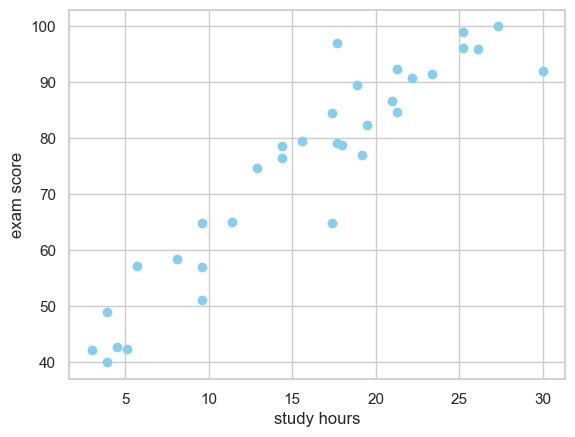

In [194]:
plt.scatter(df['Study Hours'],df['Exam Score'],color='skyblue')
plt.xlabel('study hours')
plt.ylabel('exam score')
plt.show()

In [195]:
#indipeendet and dependet features (X,y)
#X 2 boyutlu ister
X=df[['Study Hours']]
y=df['Exam Score']
type(X)

pandas.core.frame.DataFrame

In [196]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score


In [197]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.4,random_state=42
)
X_train.shape
X_test.shape

(14, 1)

In [198]:
model=Pipeline([
    ('scaler',StandardScaler()),
    ('lin_reg',LinearRegression()),
])
model.fit(X_train,y_train)




,steps,"[('scaler', ...), ('lin_reg', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None


In [199]:
y_pred=model.predict(X_test)
mse=mean_squared_error(y_true=y_test,y_pred=y_pred)
r2=r2_score(y_true=y_test,y_pred=y_pred)
print(f'model başarı oranı:{r2:.2%}')

model başarı oranı:76.40%


In [200]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Veri Yükleme
df = pd.read_csv('2-multiplegradesdataset.csv')

# 2. Özellikler ve Hedef Değişken
features = ['Study Hours', 'Sleep Hours', 'Attendance Rate', 'Social Media Hours']
X = df[features]
y = df['Exam Score']

# 3. Train-Test Ayrımı
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Pipeline Kurulumu ve Eğitim
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('reg', LinearRegression())
])

pipe.fit(X_train, y_train)

# 5. Tahmin ve Metrikler
y_pred = pipe.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"R² Skoru (Açıklanan Varyans): {r2:.4f}")
print(f"RMSE (Ortalama Hata Sapması): {rmse:.2f} puan")
print(f"MAE (Ortalama Mutlak Hata)  : {mae:.2f} puan")

# 6. Özellik Katsayıları (Feature Importance)
coefficients = pd.Series(pipe.named_steps['reg'].coef_, index=features)
print("\nÖlçeklendirilmiş Katsayılar (Etki Büyüklüğü):")
print(coefficients.sort_values(ascending=False))

R² Skoru (Açıklanan Varyans): 0.8702
RMSE (Ortalama Hata Sapması): 3.84 puan
MAE (Ortalama Mutlak Hata)  : 3.17 puan

Ölçeklendirilmiş Katsayılar (Etki Büyüklüğü):
Study Hours           10.119541
Attendance Rate        2.467557
Sleep Hours            1.229809
Social Media Hours    -3.600198
dtype: float64


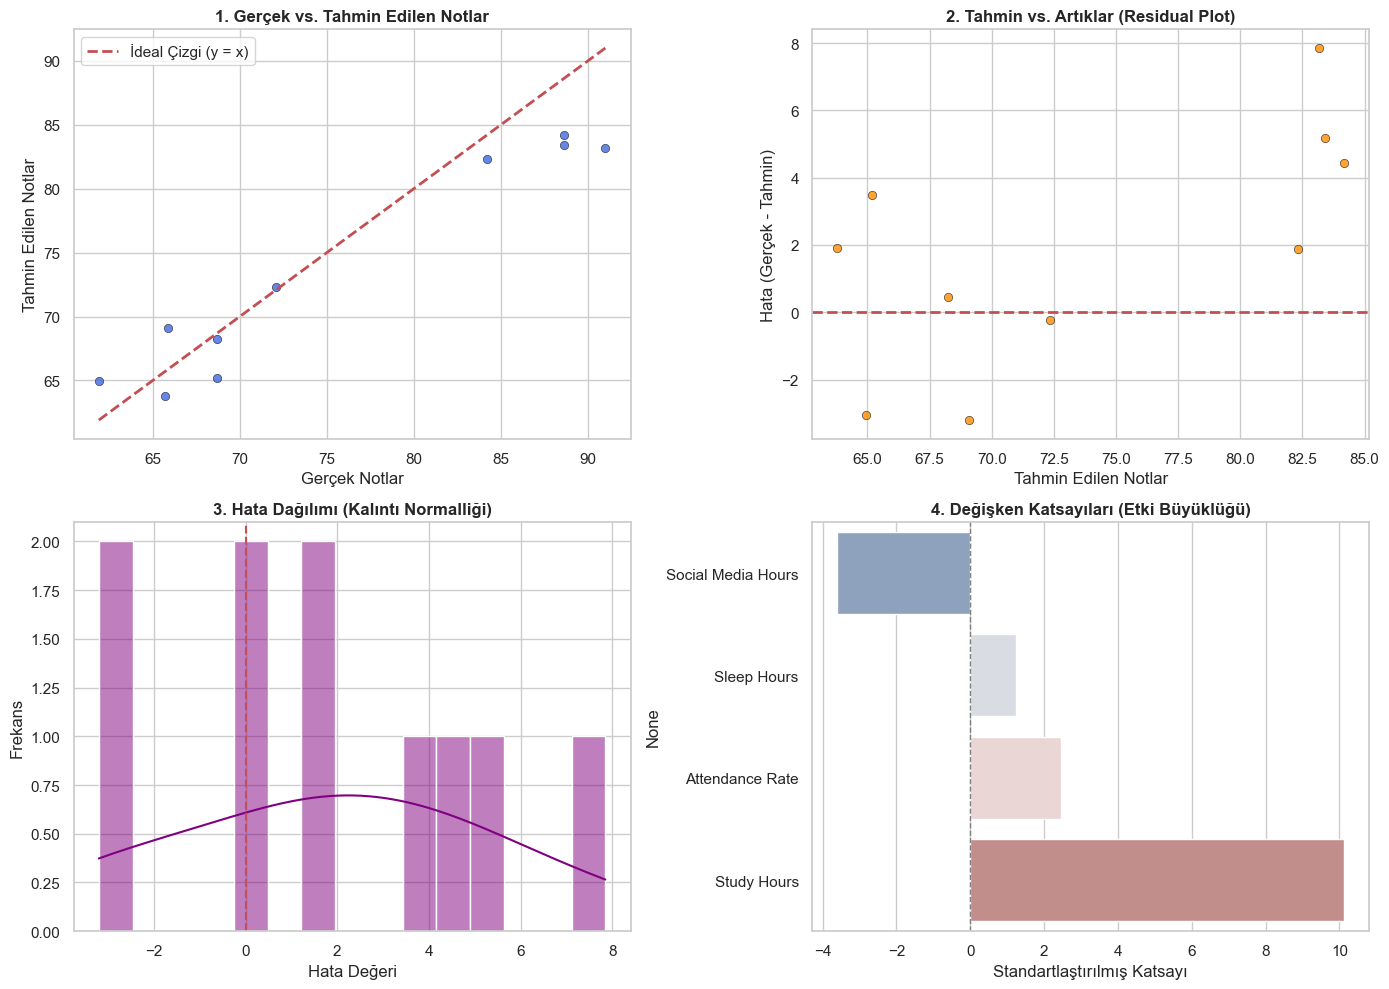

In [201]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Görselleştirme stil ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10

# Hataları (Artıklar / Residuals) hesaplama
residuals = y_test - y_pred

# 2x2 Tanı Paneli
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Gerçek vs. Tahmin Edilen Değerler
sns.scatterplot(
    x=y_test, y=y_pred, ax=axes[0, 0], color='royalblue', alpha=0.8, edgecolor='k'
)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
axes[0, 0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='İdeal Çizgi (y = x)')
axes[0, 0].set_title('1. Gerçek vs. Tahmin Edilen Notlar', fontweight='bold')
axes[0, 0].set_xlabel('Gerçek Notlar')
axes[0, 0].set_ylabel('Tahmin Edilen Notlar')
axes[0, 0].legend()

# 2. Artık (Residual) Grafiği (Homoscedasticity Kontrolü)
sns.scatterplot(
    x=y_pred, y=residuals, ax=axes[0, 1], color='darkorange', alpha=0.8, edgecolor='k'
)
axes[0, 1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[0, 1].set_title('2. Tahmin vs. Artıklar (Residual Plot)', fontweight='bold')
axes[0, 1].set_xlabel('Tahmin Edilen Notlar')
axes[0, 1].set_ylabel('Hata (Gerçek - Tahmin)')

# 3. Hata Dağılımı (Normallik Varsayımı)
sns.histplot(residuals, kde=True, ax=axes[1, 0], color='purple', bins=15)
axes[1, 0].axvline(x=0, color='r', linestyle='--', lw=1.5)
axes[1, 0].set_title('3. Hata Dağılımı (Kalıntı Normalliği)', fontweight='bold')
axes[1, 0].set_xlabel('Hata Değeri')
axes[1, 0].set_ylabel('Frekans')

# 4. Özellik Katsayıları (Feature Importance)
coef_series = pd.Series(pipe.named_steps['reg'].coef_, index=features).sort_values()
sns.barplot(
    x=coef_series.values, y=coef_series.index, ax=axes[1, 1], palette='vlag', hue=coef_series.index, legend=False
)
axes[1, 1].axvline(0, color='grey', linestyle='--', lw=1)
axes[1, 1].set_title('4. Değişken Katsayıları (Etki Büyüklüğü)', fontweight='bold')
axes[1, 1].set_xlabel('Standartlaştırılmış Katsayı')

plt.tight_layout()
plt.show()

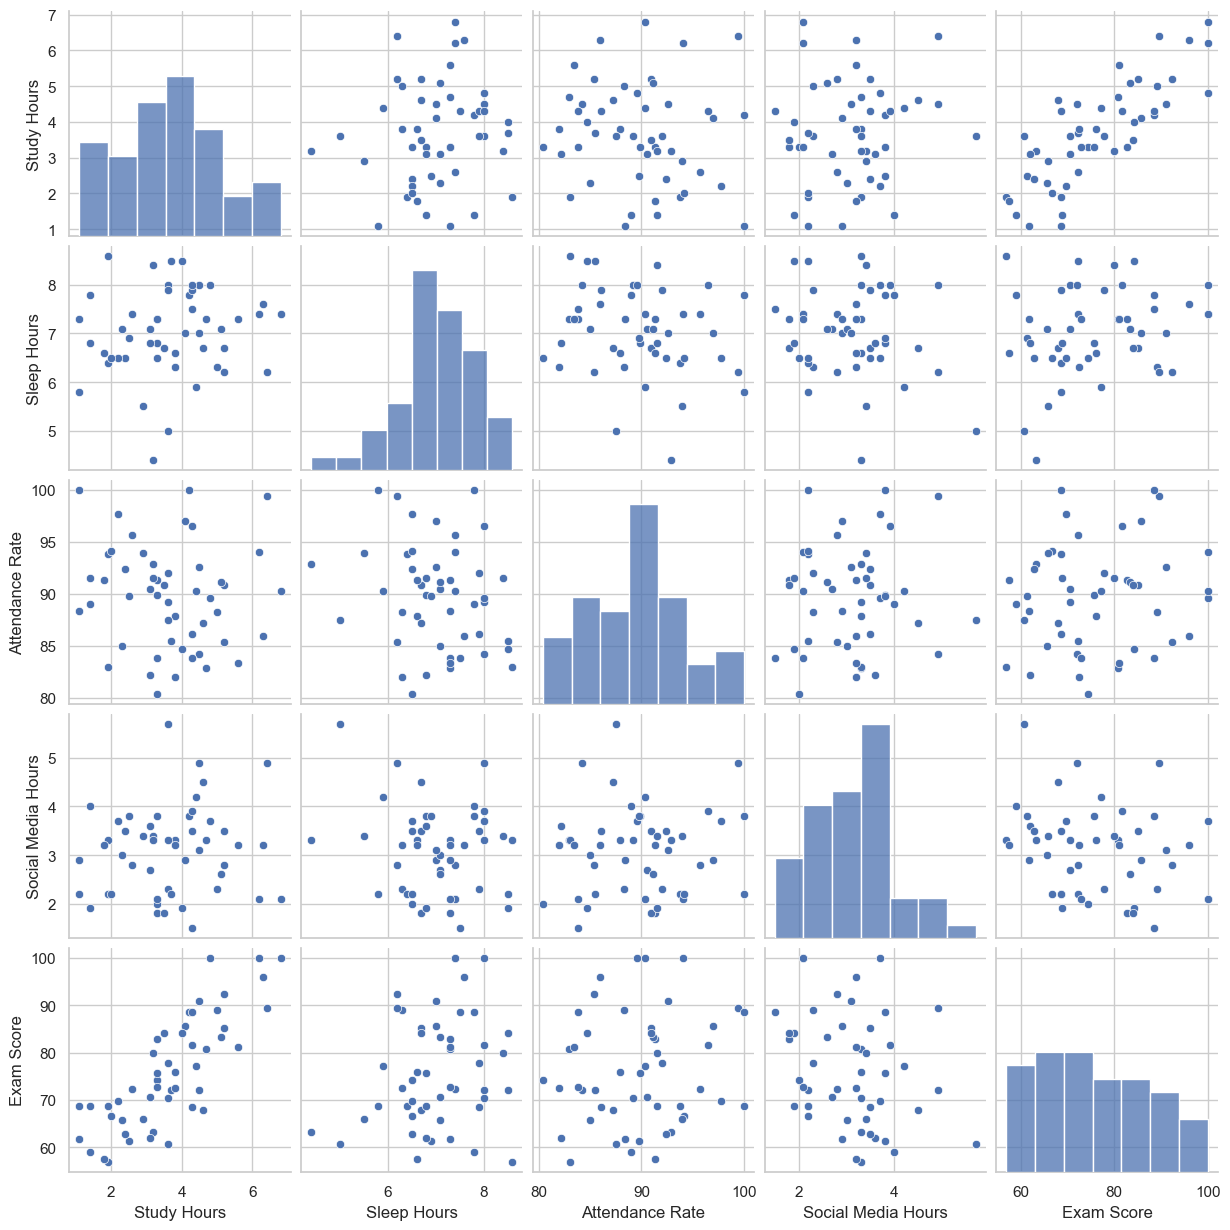

In [202]:
sns.pairplot(df)

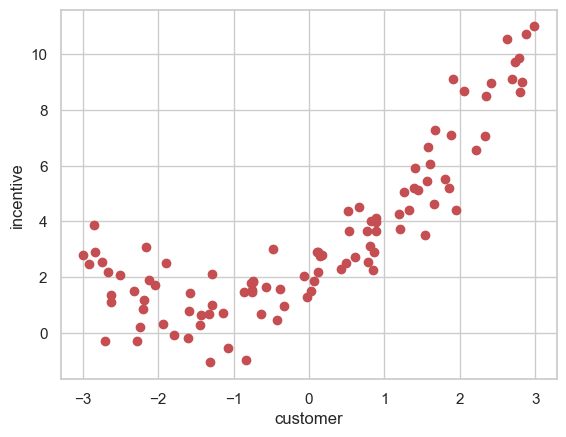

In [203]:
#poly reg
import pandas as pd
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures

df=pd.read_csv('3-customersatisfaction.csv')
plt.scatter(df['Customer Satisfaction'],df['Incentive'],color='r')
plt.xlabel('customer')
plt.ylabel('incentive')
plt.show()

In [204]:
#poly reg
import pandas as pd
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures

df=pd.read_csv('3-customersatisfaction.csv')


X=df[['Customer Satisfaction']]
y=df['Incentive']
X_train,X_test,y_train,y_test=train_test_split(
    X,y,train_size=0.8,random_state=42
)
def poly_reg(degree):
    poly=PolynomialFeatures(degree=degree)
    scaler=StandardScaler()
    lin_reg=LinearRegression()
    pipe=Pipeline([
        ('poly',poly),
        ('scaler',scaler),
        ('lin_reg',lin_reg)
    ])
    pipe.fit(X_train,y_train)
    y_pred=pipe.predict(X_test)
    r2=r2_score(y_test,y_pred)
    return r2
results=[]
for degree in range(0,10):
    score=poly_reg(degree)
    results.append((degree,score))#tuple hale getir
    sorted_results = sorted(results, key=lambda x: x[1], reverse=True)#anahtar değere göre valuelerini sırala .true (büyükten küçüğe)

for degree, score in sorted_results:
  print(f'Derece {degree}: {score:.2%}')
    



Derece 5: 96.67%
Derece 4: 96.65%
Derece 3: 96.61%
Derece 6: 96.49%
Derece 2: 96.32%
Derece 8: 94.99%
Derece 7: 94.89%
Derece 9: 93.58%
Derece 1: 73.74%
Derece 0: -1.83%


In [205]:
#Ridge regresyon (L2 regularizasyonu)
#ridge overfittingi önlemek için denklemin katsayılarını minimize eder.
#lambda L2 değeri ceza katsayıdır. lambda büyüdükçe modelin ağırlıkları küçülür

#ridge regresyon outlierlara karşı dayanıklıdır.
#çoklu doğrusal regresyonda korealsyon sorunlarını azaltır

#lambda =0 doğrusal reg
# lambda arttıkça katsayılar 0a yaklaşır fakat sıfır olmaz. 

#L2 regularizasyonu ile model karmaşıklığını kontrol eder.
# λ hiperparametresi ile model ayarlanabilir.


In [206]:
#lasso l1 regularisyon 
# lasso  hem aşırı öğrenmeyi azaltır hemde özellik seçimi sağlar. bu yönüyle
#özellikle çok sayıda  değişkene sahip datalarda oldukça etkildiir
#ridgeden farklı olarak ilişkilendiremediği katsayıları 0 yapar.
#7 Lasso Regresyon (L1)


In [207]:
#elasticnet ridge ve lasso karışımıdır.



ÇAPRAZ DOĞRULAMA /CROSS VALIDATION

In [208]:
#amaç modelin performansını arttırmak 
# en çok kullanılan yöntem 
#K FOLD CROSS validation 

#veri seti  k eşit parçaya bölünür . 
#her sefeerinde bir parça doğrulamak için 
#dieğrleri eğitmek için kullanılır . 
# bu işlem k kez tekrarlanır 
# dengeli doğrulama sağlar 


In [209]:
df=pd.read_csv('4-Algerian_forest_fires_dataset.csv')
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
0,1,6,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire
4,5,6,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire


In [210]:
df.isnull().sum()

day            1
month          2
year           2
Temperature    2
 RH            2
 Ws            2
Rain           2
FFMC           2
DMC            2
DC             2
ISI            2
BUI            2
FWI            2
Classes        3
dtype: int64

In [211]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247 entries, 0 to 246
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   day          246 non-null    object
 1   month        245 non-null    object
 2   year         245 non-null    object
 3   Temperature  245 non-null    object
 4    RH          245 non-null    object
 5    Ws          245 non-null    object
 6   Rain         245 non-null    object
 7   FFMC         245 non-null    object
 8   DMC          245 non-null    object
 9   DC           245 non-null    object
 10  ISI          245 non-null    object
 11  BUI          245 non-null    object
 12  FWI          245 non-null    object
 13  Classes      244 non-null    object
dtypes: object(14)
memory usage: 27.1+ KB


(247, 14)

In [212]:
df.drop(df.index[122], inplace=True)
df.shape

(246, 14)

In [213]:
df.loc[:123,'Region']=0
df.loc[123:,'Region']=1
df

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0.0
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire,0.0
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0.0
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire,0.0
4,5,6,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
242,26,9,2012,30,65,14,0,85.4,16,44.5,4.5,16.9,6.5,fire,1.0
243,27,9,2012,28,87,15,4.4,41.1,6.5,8,0.1,6.2,0,not fire,1.0
244,28,9,2012,27,87,29,0.5,45.9,3.5,7.9,0.4,3.4,0.2,not fire,1.0
245,29,9,2012,24,54,18,0.1,79.7,4.3,15.2,1.7,5.1,0.7,not fire,1.0


In [214]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 246 entries, 0 to 246
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   day          246 non-null    object 
 1   month        245 non-null    object 
 2   year         245 non-null    object 
 3   Temperature  245 non-null    object 
 4    RH          245 non-null    object 
 5    Ws          245 non-null    object 
 6   Rain         245 non-null    object 
 7   FFMC         245 non-null    object 
 8   DMC          245 non-null    object 
 9   DC           245 non-null    object 
 10  ISI          245 non-null    object 
 11  BUI          245 non-null    object 
 12  FWI          245 non-null    object 
 13  Classes      244 non-null    object 
 14  Region       246 non-null    float64
dtypes: float64(1), object(14)
memory usage: 38.9+ KB


In [215]:
# Sayısala çevrilmek istenen sütunlar
numeric_cols = [col for col in df.columns if col != 'Classes']

# errors='coerce' dönüştürülemeyen hatalı metinleri NaN (boş değer) yapar
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [216]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 246 entries, 0 to 246
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   day          244 non-null    float64
 1   month        244 non-null    float64
 2   year         244 non-null    float64
 3   Temperature  244 non-null    float64
 4    RH          244 non-null    float64
 5    Ws          244 non-null    float64
 6   Rain         244 non-null    float64
 7   FFMC         244 non-null    float64
 8   DMC          244 non-null    float64
 9   DC           243 non-null    float64
 10  ISI          244 non-null    float64
 11  BUI          244 non-null    float64
 12  FWI          243 non-null    float64
 13  Classes      0 non-null      float64
 14  Region       246 non-null    float64
dtypes: float64(15)
memory usage: 38.9 KB


In [217]:
df.isnull().sum()

day              2
month            2
year             2
Temperature      2
 RH              2
 Ws              2
Rain             2
FFMC             2
DMC              2
DC               3
ISI              2
BUI              2
FWI              3
Classes        246
Region           0
dtype: int64

In [218]:
# Tüm sütun adlarının başındaki ve sonundaki boşlukları temizleyin
df.columns = df.columns.str.strip()

# Ardından işleminizi tekrar çalıştırın
df['Classes'] = df['Classes'].fillna(0)

In [219]:
df.isnull().sum()

day            2
month          2
year           2
Temperature    2
RH             2
Ws             2
Rain           2
FFMC           2
DMC            2
DC             3
ISI            2
BUI            2
FWI            3
Classes        0
Region         0
dtype: int64

In [220]:
df=df.dropna().reset_index(drop=True)


In [221]:
df.isnull().sum()

day            0
month          0
year           0
Temperature    0
RH             0
Ws             0
Rain           0
FFMC           0
DMC            0
DC             0
ISI            0
BUI            0
FWI            0
Classes        0
Region         0
dtype: int64

In [222]:
df.shape

(243, 15)

In [223]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   day          243 non-null    float64
 1   month        243 non-null    float64
 2   year         243 non-null    float64
 3   Temperature  243 non-null    float64
 4   RH           243 non-null    float64
 5   Ws           243 non-null    float64
 6   Rain         243 non-null    float64
 7   FFMC         243 non-null    float64
 8   DMC          243 non-null    float64
 9   DC           243 non-null    float64
 10  ISI          243 non-null    float64
 11  BUI          243 non-null    float64
 12  FWI          243 non-null    float64
 13  Classes      243 non-null    float64
 14  Region       243 non-null    float64
dtypes: float64(15)
memory usage: 28.6 KB


In [224]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
day,243.0,15.761317,8.842552,1.0,8.00,16.0,23.00,31.0
month,243.0,7.502058,1.114793,6.0,7.00,8.0,8.00,9.0
year,243.0,2012.000000,0.000000,2012.0,2012.00,2012.0,2012.00,2012.0
Temperature,243.0,32.152263,3.628039,22.0,30.00,32.0,35.00,42.0
RH,243.0,62.041152,14.828160,21.0,52.50,63.0,73.50,90.0
Ws,243.0,15.493827,2.811385,6.0,14.00,15.0,17.00,29.0
Rain,243.0,0.762963,2.003207,0.0,0.00,0.0,0.50,16.8
FFMC,243.0,77.842387,14.349641,28.6,71.85,83.3,88.30,96.0
DMC,243.0,14.680658,12.393040,0.7,5.80,11.3,20.80,65.9
DC,243.0,49.430864,47.665606,6.9,12.35,33.1,69.10,220.4


In [225]:
df['Classes'].value_counts()

Classes
0.0    243
Name: count, dtype: int64

In [226]:
df.corr()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
day,1.000000,-0.000369,NaN,0.097227,-0.076034,0.047812,-0.112523,0.224956,0.491514,0.527952,0.180543,0.517117,0.350781,NaN,0.000821
month,-0.000369,1.000000,NaN,-0.056781,-0.041252,-0.039880,0.034822,0.017030,0.067943,0.126511,0.065608,0.085073,0.082639,NaN,0.001857
year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temperature,0.097227,-0.056781,NaN,1.000000,-0.651400,-0.284510,-0.326492,0.676568,0.485687,0.376284,0.603871,0.459789,0.566670,NaN,0.269555
RH,-0.076034,-0.041252,NaN,-0.651400,1.000000,0.244048,0.222356,-0.644873,-0.408519,-0.226941,-0.686667,-0.353841,-0.580957,NaN,-0.402682
Ws,0.047812,-0.039880,NaN,-0.284510,0.244048,1.000000,0.171506,-0.166548,-0.000721,0.079135,0.008532,0.031438,0.032368,NaN,-0.181160
Rain,-0.112523,0.034822,NaN,-0.326492,0.222356,0.171506,1.000000,-0.543906,-0.288773,-0.298023,-0.347484,-0.299852,-0.324422,NaN,-0.040013
FFMC,0.224956,0.017030,NaN,0.676568,-0.644873,-0.166548,-0.543906,1.000000,0.603608,0.507397,0.740007,0.592011,0.691132,NaN,0.222241
DMC,0.491514,0.067943,NaN,0.485687,-0.408519,-0.000721,-0.288773,0.603608,1.000000,0.875925,0.680454,0.982248,0.875864,NaN,0.192089
DC,0.527952,0.126511,NaN,0.376284,-0.226941,0.079135,-0.298023,0.507397,0.875925,1.000000,0.508643,0.941988,0.739521,NaN,-0.078734


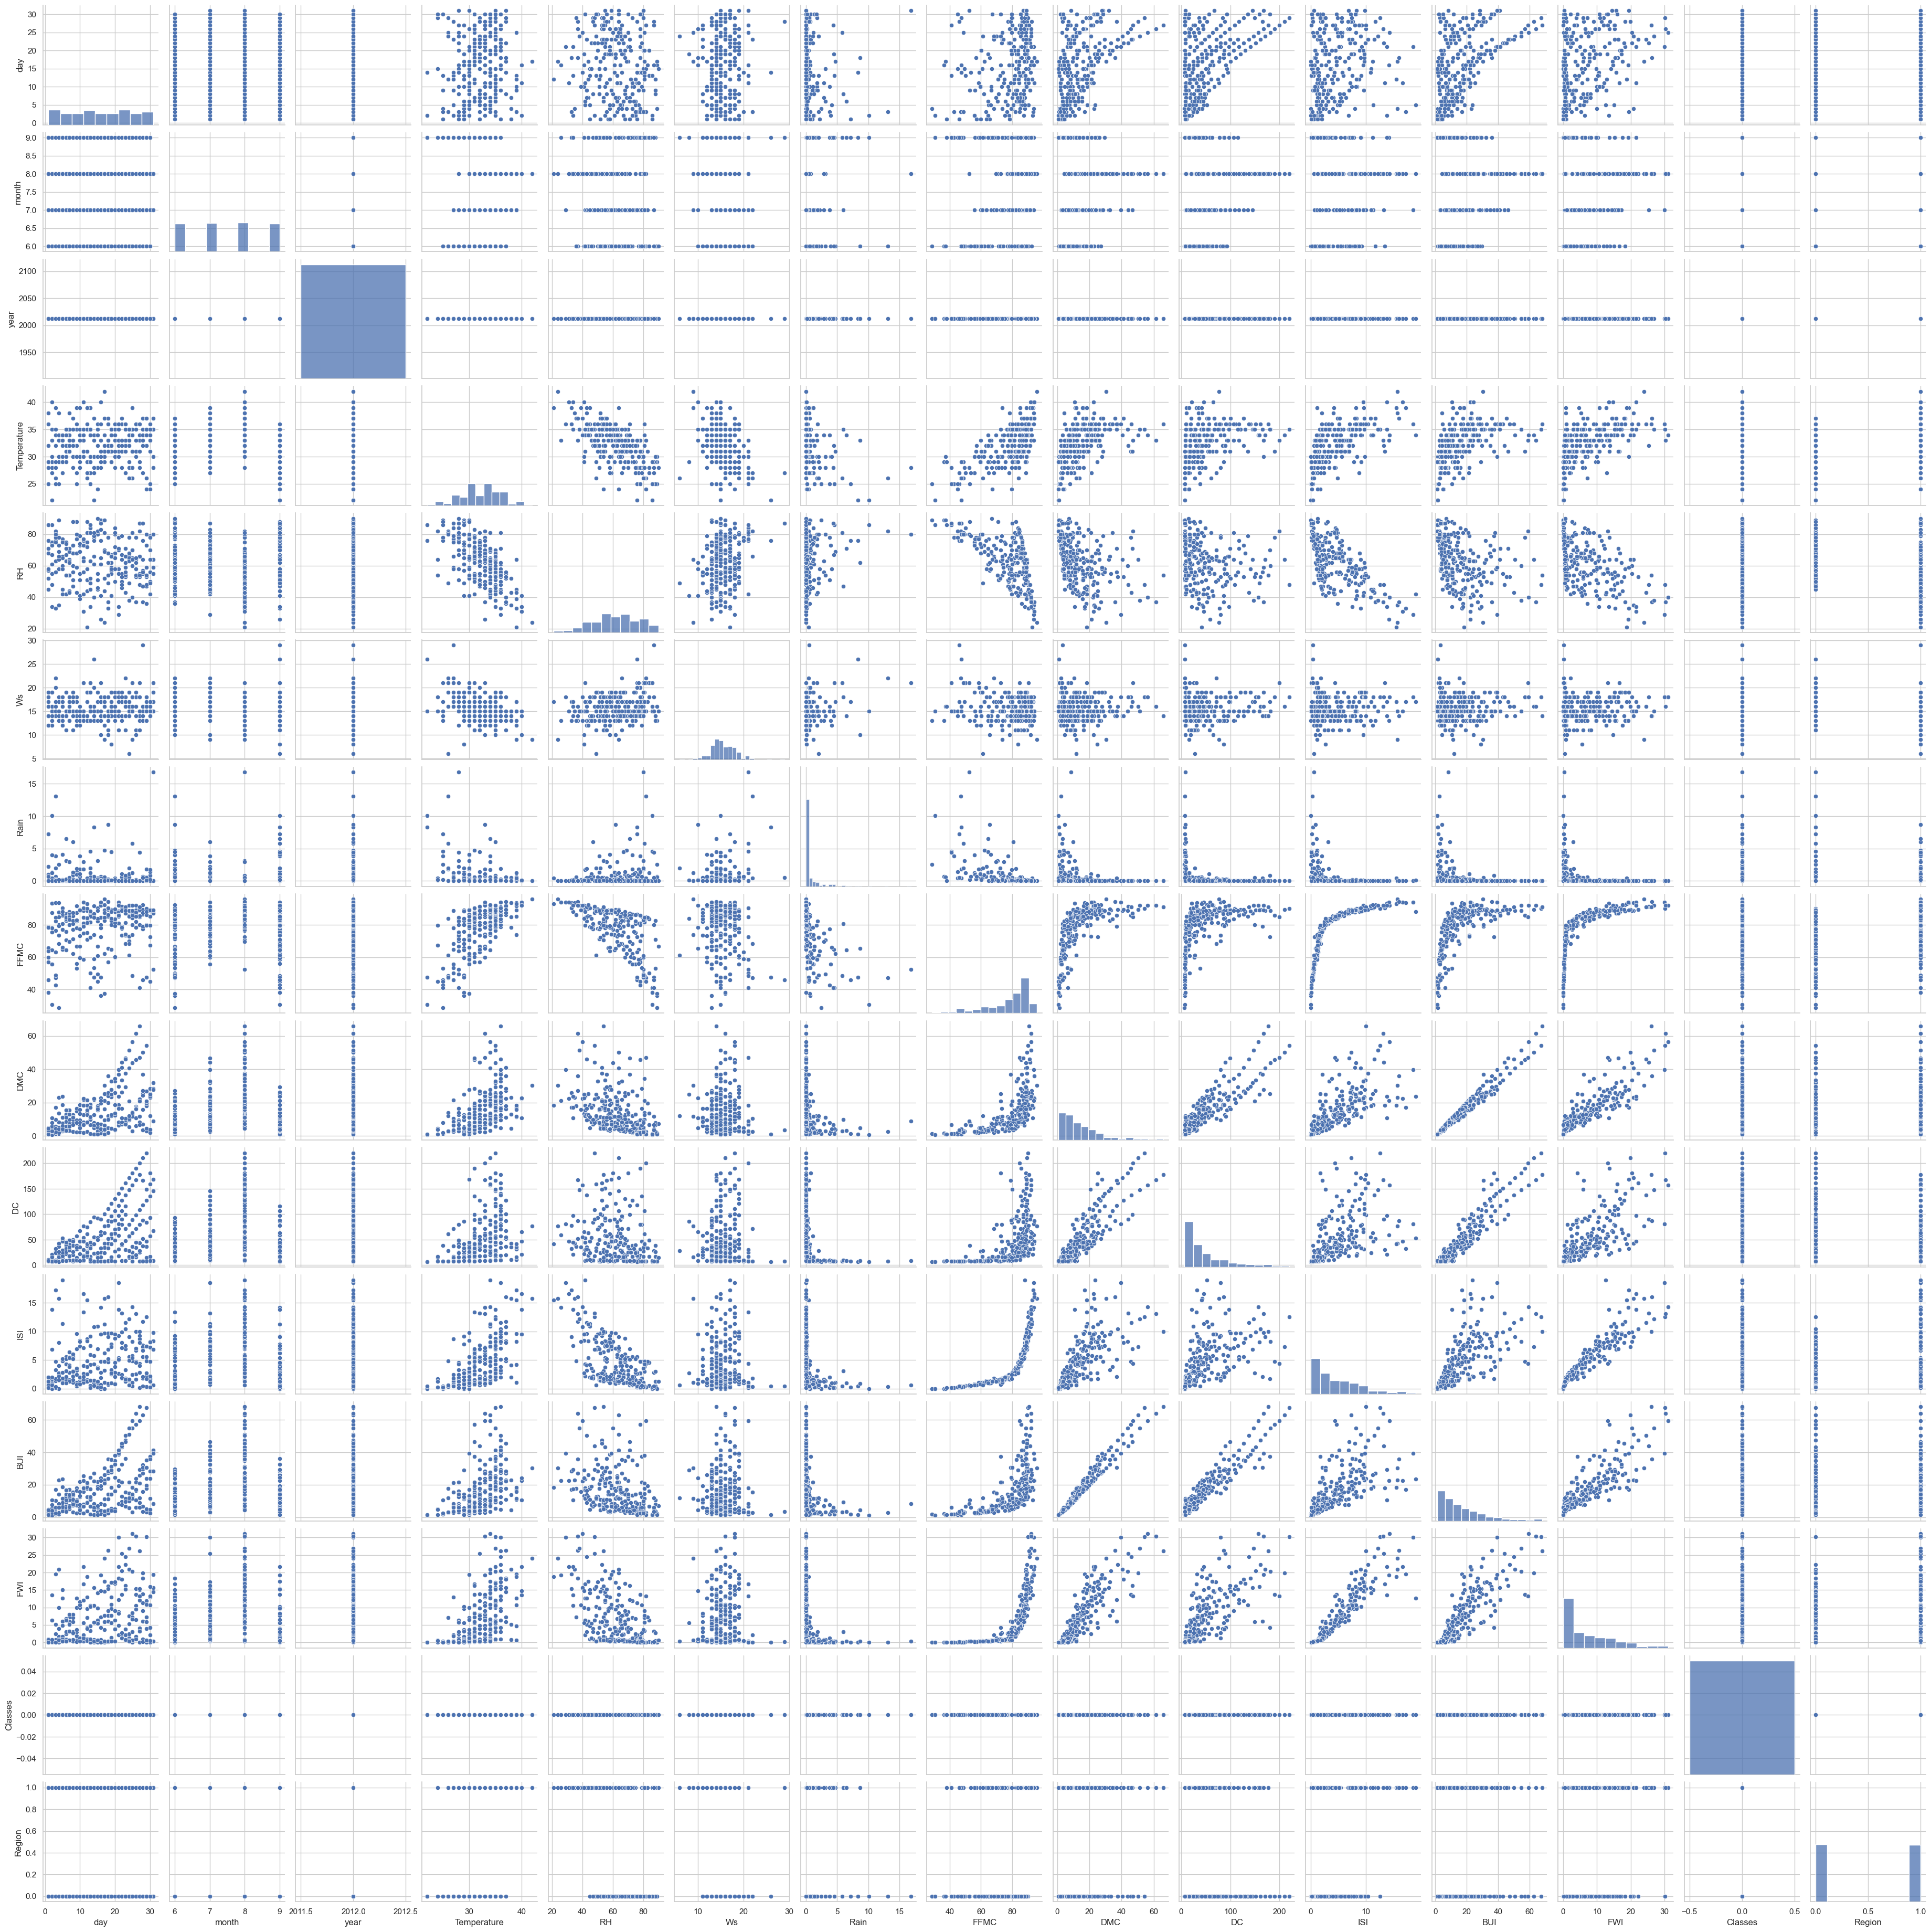

In [227]:
sns.pairplot(df)
plt.show()

In [228]:
from matplotlib.pyplot import axis
#gerekrisz daata silme 


df.drop(['day','month','year'],axis=1, inplace=True)


In [229]:
df

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29.0,57.0,18.0,0.0,65.7,3.4,7.6,1.3,3.4,0.5,0.0,0.0
1,29.0,61.0,13.0,1.3,64.4,4.1,7.6,1.0,3.9,0.4,0.0,0.0
2,26.0,82.0,22.0,13.1,47.1,2.5,7.1,0.3,2.7,0.1,0.0,0.0
3,25.0,89.0,13.0,2.5,28.6,1.3,6.9,0.0,1.7,0.0,0.0,0.0
4,27.0,77.0,16.0,0.0,64.8,3.0,14.2,1.2,3.9,0.5,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
238,30.0,65.0,14.0,0.0,85.4,16.0,44.5,4.5,16.9,6.5,0.0,1.0
239,28.0,87.0,15.0,4.4,41.1,6.5,8.0,0.1,6.2,0.0,0.0,1.0
240,27.0,87.0,29.0,0.5,45.9,3.5,7.9,0.4,3.4,0.2,0.0,1.0
241,24.0,54.0,18.0,0.1,79.7,4.3,15.2,1.7,5.1,0.7,0.0,1.0


In [230]:

import pandas as pd
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression,Lasso,Ridge,ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures

#yüksek korealsyonlu kolonlar  train ksımında gereksiz eğitim seti oluşturur bu yüzden drop etmek gerekir
X=df.drop(['FWI','Classes','BUI','DC'],axis=1)
y=df['FWI']
X_train,X_test,y_train,y_test=train_test_split(
    X,y,train_size=0.75,random_state=42
)
print(X_train.shape)
print(X_test.shape)
X_train.corr()

(182, 8)
(61, 8)


,Temperature,RH,Ws,Rain,FFMC,DMC,ISI,Region
Temperature,1.000000,-0.656095,-0.305977,-0.317512,0.694768,0.498173,0.629848,0.254549
RH,-0.656095,1.000000,0.225736,0.241656,-0.653023,-0.414601,-0.717804,-0.394665
Ws,-0.305977,0.225736,1.000000,0.251932,-0.190076,0.000379,-0.023558,-0.199969
Rain,-0.317512,0.241656,0.251932,1.000000,-0.545491,-0.289754,-0.345707,-0.059022
FFMC,0.694768,-0.653023,-0.190076,-0.545491,1.000000,0.620807,0.750799,0.249514
DMC,0.498173,-0.414601,0.000379,-0.289754,0.620807,1.000000,0.685656,0.212582
ISI,0.629848,-0.717804,-0.023558,-0.345707,0.750799,0.685656,1.000000,0.296441
Region,0.254549,-0.394665,-0.199969,-0.059022,0.249514,0.212582,0.296441,1.000000


In [231]:
model=Pipeline([
    ('scaler',StandardScaler()),
    ('lin_reg',LinearRegression())
])
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print(f'mae:{mae:.2%}')
print(f'mse:{mse:.2%}')
print(f'r2:{r2:.2%}')

mae:58.06%
mse:75.10%
r2:98.30%


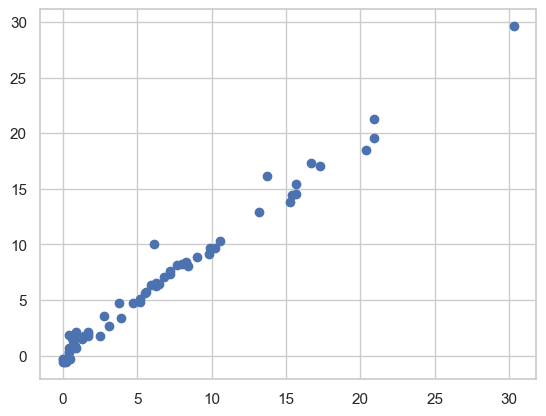

In [232]:
plt.scatter(y_test,y_pred)
plt.show()

In [233]:
model=Pipeline([
    ('scaler',StandardScaler()),
    ('lasso',Lasso())
])
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print(f'mae:{mae:.2%}')
print(f'mse:{mse:.2%}')
print(f'r2:{r2:.2%}')

mae:113.32%
mse:224.83%
r2:94.92%


In [234]:
model=Pipeline([
    ('scaler',StandardScaler()),
    ('Ridge',Ridge())
])
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print(f'mae:{mae:.2%}')
print(f'mse:{mse:.2%}')
print(f'r2:{r2:.2%}')

mae:59.70%
mse:77.50%
r2:98.25%


In [235]:
model=Pipeline([
    ('scaler',StandardScaler()),
    ('Elastic_net',ElasticNet())
])
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print(f'mae:{mae:.2%}')
print(f'mse:{mse:.2%}')
print(f'r2:{r2:.2%}')

mae:192.84%
mse:581.30%
r2:86.87%


In [236]:
#lasso ridge eleastic crossv
from sklearn.linear_model import LassoCV,RidgeCV,ElasticNetCV
model=Pipeline([
    ('scaler',StandardScaler()),
    ('lasso',LassoCV(cv=5))
])
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print(f'mae:{mae:.2%}')
print(f'mse:{mse:.2%}')
print(f'r2:{r2:.2%}')

mae:62.98%
mse:82.35%
r2:98.14%


In [237]:
model=Pipeline([
    ('scaler',StandardScaler()),
    ('Ridgecv',RidgeCV(cv=5))
])
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print(f'mae:{mae:.2%}')
print(f'mse:{mse:.2%}')
print(f'r2:{r2:.2%}')


mae:59.70%
mse:77.50%
r2:98.25%


In [238]:
model=Pipeline([
    ('scaler',StandardScaler()),
    ('Elastic_net',ElasticNetCV(cv=5))
])
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print(f'mae:{mae:.2%}')
print(f'mse:{mse:.2%}')
print(f'r2:{r2:.2%}')

mae:67.17%
mse:90.12%
r2:97.96%


In [239]:
# from lazypredict.Supervised import LazyClassifier
# from sklearn.datasets import load_breast_cancer
# from sklearn.model_selection import train_test_split

# # Örnek veri setini yükle
# data = load_breast_cancer()
# X = data.data
# y = data.target

# # 1. Veriyi eğitim (%80) ve test (%20) olarak ayır
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# # 2. LazyClassifier'ı tanımla ve tüm modelleri eğit
# clf = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None)
# models, predictions = clf.fit(X_train, X_test, y_train, y_test)

# # 3. Tüm modellerin başarı sıralamasını yazdır
# print(models)